# Life expectancy and missing birth and death dates

In [1]:
import tempfile
import numpy as np
import polars as pl
import duckdb
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from style import *

DB_PATH = '../data/cultura/cultura_enriched_v3.2.duckdb'
CENTURY = 100
MIN_LIVES = 10
LIFE_MIN, LIFE_MAX = 0, 110
CURRENT_YEAR, OLDEST_AGE = 2026, 110
KNOWN = ['day', 'month', 'year', 'decade']
FIRST_CENTURY = -800
CUTOFF = 1500
LAST_BIRTH_CENTURY = 1900
LAST_BIRTH_YEAR = 1920
META_OCCUPATIONS = list(OCCUPATION_COLORS)
ALL = 'All'

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(12)
apply_style()

## Load the data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE list_contains($meta_occupations, occupation.meta_occupation)
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    dates AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS wikidata_birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS wikidata_death
        FROM individual
    )
    SELECT dates.qid,
           coalesce(main_meta_occupation.meta_occupation, $all) AS meta_occupation,
           coalesce(dates.wikidata_birth[1].year, dates.wikidata_death[1].year) AS first_year,
           len(dates.wikidata_birth) = 0 AS no_birth,
           len(dates.wikidata_death) = 0 AS no_death,
           list_filter(dates.wikidata_birth, d -> list_contains($known, d.precision))[1].year AS birth_year,
           list_filter(dates.wikidata_death, d -> list_contains($known, d.precision))[1].year AS death_year
    FROM dates
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = dates.qid
''', params={'known': KNOWN, 'meta_occupations': META_OCCUPATIONS, 'all': ALL}).pl()
con.close()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')

13,002,897 individuals


## 1. Missing birth and death dates

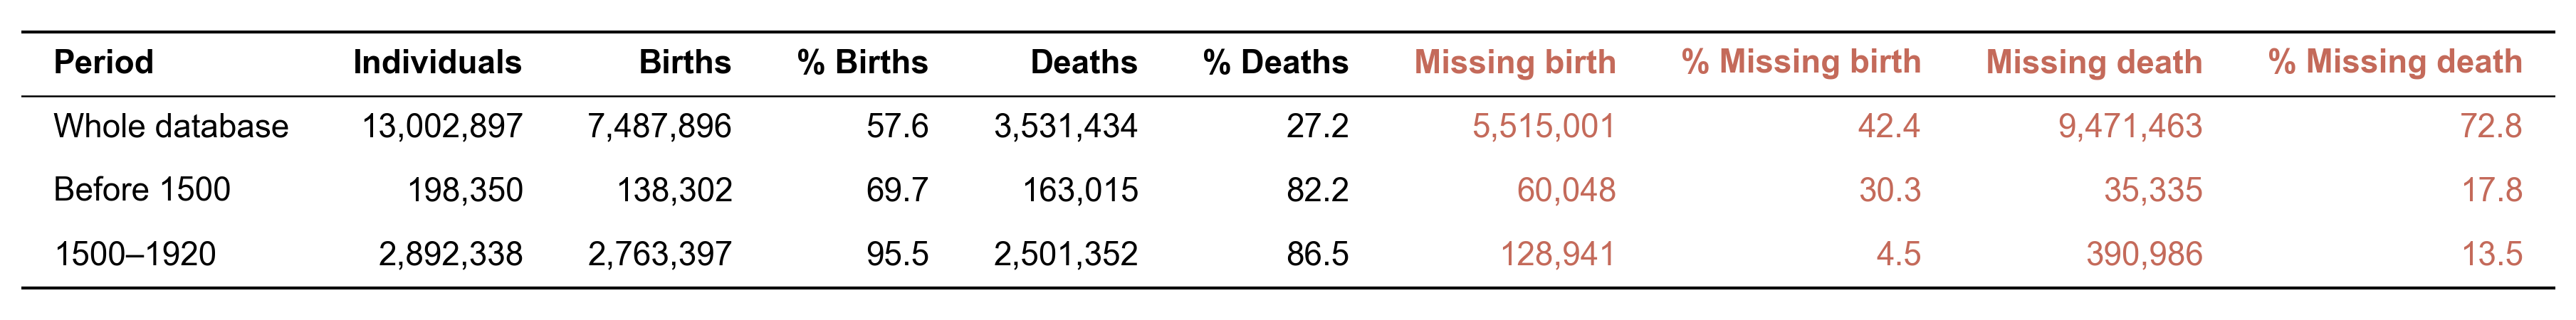

In [3]:
def date_counts(period, frame):
    births, deaths = int((~frame['no_birth']).sum()), int((~frame['no_death']).sum())
    return {
        'Period': period,
        'Individuals': frame.height,
        'Births': births,
        '% Births': round(100 * births / frame.height, 1),
        'Deaths': deaths,
        '% Deaths': round(100 * deaths / frame.height, 1),
        'Missing birth': frame.height - births,
        '% Missing birth': round(100 * (frame.height - births) / frame.height, 1),
        'Missing death': frame.height - deaths,
        '% Missing death': round(100 * (frame.height - deaths) / frame.height, 1),
    }


date_table = pl.DataFrame([
    date_counts('Whole database', people),
    date_counts(f'Before {CUTOFF}', people.filter(pl.col('first_year') < CUTOFF)),
    date_counts(f'{CUTOFF}–{LAST_BIRTH_YEAR}', people.filter(pl.col('first_year').is_between(CUTOFF, LAST_BIRTH_YEAR))),
])
show_table(date_table, decimals=1, red_columns=['Missing birth', '% Missing birth', 'Missing death', '% Missing death'])

In [4]:
def century_label(start):
    end = min(start + CENTURY - 1, LAST_BIRTH_YEAR)
    return f'{start}–{end}' if start >= 0 else f'{-start}–{-end} BC'


def per_century(frame, anchor, name):
    return frame.filter(pl.col(anchor).is_between(FIRST_CENTURY, LAST_BIRTH_YEAR)).group_by((pl.col(anchor) // CENTURY * CENTURY).alias('century')).agg(pl.len().alias(name))


missing_death = people.filter(pl.col('no_death') & pl.col('birth_year').is_not_null())
missing_birth = people.filter(pl.col('no_birth') & pl.col('death_year').is_not_null())
missing = (
    per_century(missing_death, 'birth_year', 'missing death')
    .join(per_century(missing_birth, 'death_year', 'missing birth'), on='century', how='full', coalesce=True)
    .fill_null(0)
    .sort('century')
)
print(f'{missing_death.height:,} missing a death have a birth, {missing_birth.height:,} missing a birth have a death')
missing.with_columns(pl.col('century').map_elements(century_label, return_dtype=pl.String).alias('label'))

4,130,793 missing a death have a birth, 258,435 missing a birth have a death


century,missing death,missing birth,label
i64,u32,u32,str
-800,6,42,"""800–701 BC"""
-700,6,71,"""700–601 BC"""
-600,34,87,"""600–501 BC"""
-500,20,92,"""500–401 BC"""
-400,40,113,"""400–301 BC"""
-300,69,146,"""300–201 BC"""
-200,81,121,"""200–101 BC"""
-100,122,178,"""100–1 BC"""
0,95,281,"""0–99"""


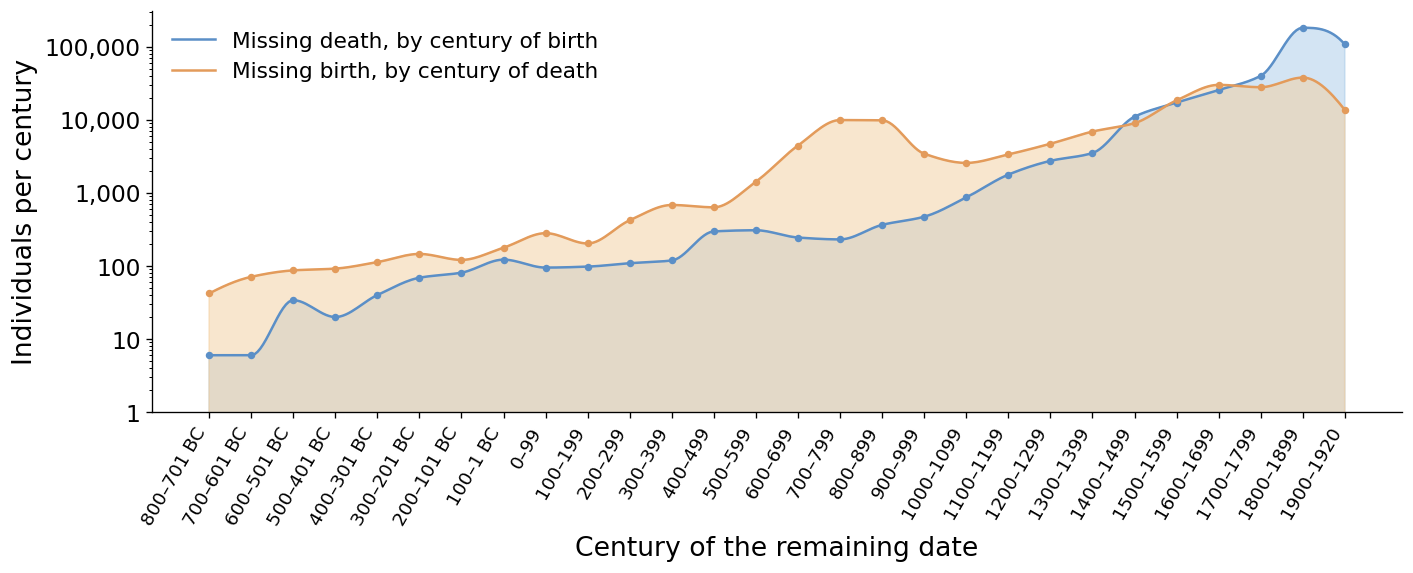

In [5]:
def set_century_axis(ax, starts):
    ax.set_xticks(starts)
    ax.set_xticklabels([century_label(start) for start in starts], rotation=60, ha='right', fontsize=14)


def smooth(x, y, points=400):
    fine = np.linspace(x.min(), x.max(), points)
    return fine, 10 ** PchipInterpolator(x, np.log10(np.maximum(y, 1)))(fine)


fig, ax = plt.subplots(figsize=FIGSIZE)
middle = (missing['century'] + CENTURY / 2).to_numpy()
for column, label, line, fill in [('missing death', 'Missing death, by century of birth', BLUE, LIGHT_BLUE),
                                  ('missing birth', 'Missing birth, by century of death', ORANGE, LIGHT_ORANGE)]:
    x, y = smooth(middle, missing[column].to_numpy())
    ax.fill_between(x, y, color=fill, alpha=0.5)
    ax.plot(x, y, color=line, linewidth=1.5, label=label)
    ax.scatter(middle, missing[column], color=line, s=12, zorder=3)
ax.set_yscale('log')
ax.set_ylim(bottom=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set_xticks(middle)
ax.set_xticklabels([century_label(start) for start in missing['century']], rotation=60, ha='right', fontsize=11)
ax.set_ylabel('Individuals per century')
ax.set_xlabel('Century of the remaining date')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 2. Life expectancy of the individuals with both dates

In [6]:
lives = (
    people.filter(pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null())
    .with_columns((pl.col('death_year') - pl.col('birth_year')).alias('life_expectancy'))
    .filter(pl.col('life_expectancy').is_between(LIFE_MIN, LIFE_MAX) & pl.col('meta_occupation').is_in(META_OCCUPATIONS) & (pl.col('birth_year') <= LAST_BIRTH_YEAR))
    .with_columns(
        (pl.col('birth_year') // CENTURY * CENTURY).alias('birth_century'),
        (pl.col('death_year') // CENTURY * CENTURY).alias('death_century'),
    )
)

In [7]:
analysed = lives.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS)) & pl.col('birth_century').is_between(FIRST_CENTURY, LAST_BIRTH_CENTURY))
print(f'{analysed.height:,} individuals with both dates, born {FIRST_CENTURY} to {LAST_BIRTH_YEAR}, in the four main meta occupations')
analysed.group_by('meta_occupation').agg(pl.len().alias('individuals'), pl.col('life_expectancy').mean().round(1).alias('mean life expectancy')).sort('individuals', descending=True)

1,605,237 individuals with both dates, born -800 to 1920, in the four main meta occupations


meta_occupation,individuals,mean life expectancy
str,u32,f64
"""Leadership""",626913,68.2
"""Culture""",516921,70.1
"""Discovery/Science""",358418,71.7
"""Sports/Games""",102985,70.0


In [8]:
def century_stats(frame):
    return (
        frame.group_by(pl.col('birth_century').alias('century'))
        .agg(
            pl.len().alias('individuals'),
            pl.col('life_expectancy').quantile(0.25, 'linear').alias('q1'),
            pl.col('life_expectancy').mean().alias('mean'),
            pl.col('life_expectancy').quantile(0.75, 'linear').alias('q3'),
        )
        .filter(pl.col('individuals') >= MIN_LIVES)
        .sort('century')
    )


def plot_boxes(ax, frame, color):
    rows = century_stats(frame)
    starts = rows['century'].to_list()
    values = [frame.filter(pl.col('birth_century') == start)['life_expectancy'].to_numpy() for start in starts]
    boxes = ax.boxplot(values, positions=starts, widths=CENTURY * 0.5, showfliers=False, patch_artist=True, showmeans=True, meanline=True,
                       boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color), medianprops=dict(linewidth=0),
                       meanprops=dict(color=color, linewidth=2, linestyle='-'), whiskerprops=dict(color=color), capprops=dict(color=color))
    for i, row in enumerate(rows.iter_rows(named=True)):
        x = row['century']
        ax.text(x + CENTURY * 0.28, row['mean'], f"{row['mean']:.0f}", ha='left', va='center', fontsize=14, color=color, fontweight='bold')
        ax.text(x - CENTURY * 0.28, row['q1'], f"{row['q1']:.0f}", ha='right', va='center', fontsize=12, color=TEXT)
        ax.text(x - CENTURY * 0.28, row['q3'], f"{row['q3']:.0f}", ha='right', va='center', fontsize=12, color=TEXT)
        top = boxes['caps'][2 * i + 1].get_ydata()[0]
        ax.text(x, top + 2, f"n={row['individuals']:,}", ha='center', va='bottom', fontsize=13, color=TEXT, rotation=90)
    set_century_axis(ax, starts)
    ax.set_xlim(FIRST_CENTURY - CENTURY, LAST_BIRTH_CENTURY + CENTURY)
    ax.set_ylim(LIFE_MIN, LIFE_MAX + 40)
    ax.set_ylabel('Life expectancy (years)')
    ax.grid(axis='x', visible=False)
    assert all(abs(line.get_ydata()[0] - mean) < 1e-9 for line, mean in zip(boxes['means'], rows['mean']))

In [9]:
counts = (
    analysed.group_by('birth_century', 'meta_occupation').len()
    .pivot(on='meta_occupation', index='birth_century', values='len')
    .fill_null(0).sort('birth_century')
    .select('birth_century', *OCCUPATION_COLORS)
    .with_columns(pl.sum_horizontal(list(OCCUPATION_COLORS)).alias('individuals'))
)
counts

birth_century,Culture,Discovery/Science,Leadership,Sports/Games,individuals
i64,u32,u32,u32,u32,u32
-800,2,1,12,0,15
-700,6,4,20,0,30
-600,19,21,40,0,80
-500,30,35,62,2,129
-400,37,62,95,1,195
-300,17,26,138,0,181
-200,23,34,154,0,211
-100,38,29,214,1,282
0,22,33,185,1,241


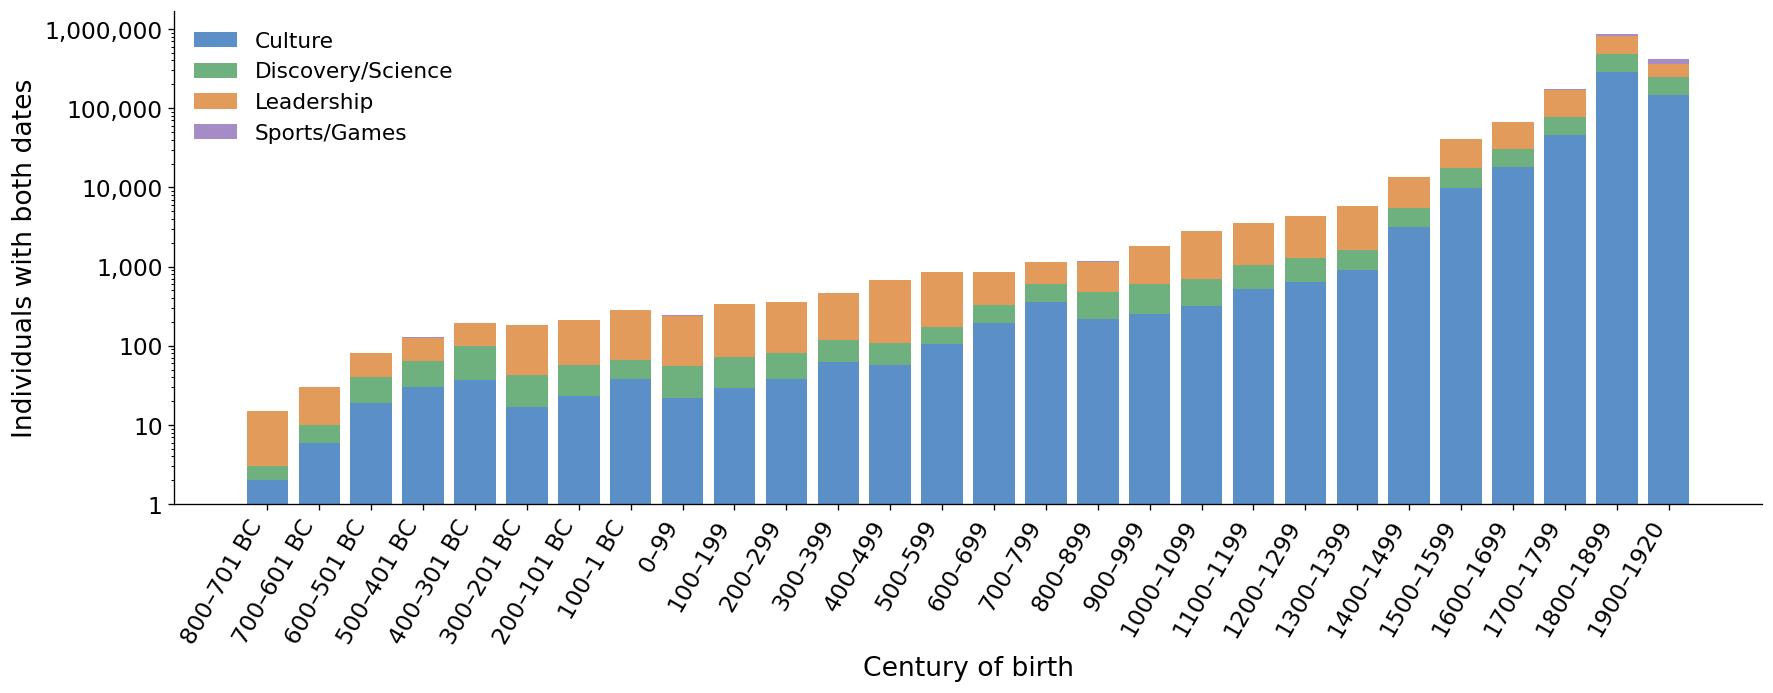

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
bottom = np.zeros(counts.height)
for occupation, color in OCCUPATION_COLORS.items():
    ax.bar(counts['birth_century'], counts[occupation], bottom=bottom, width=CENTURY * 0.8, color=color, label=occupation)
    bottom += counts[occupation].to_numpy()
ax.set_yscale('log')
ax.set_ylim(bottom=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set_ylabel('Individuals with both dates')
ax.set_xlabel('Century of birth')
set_century_axis(ax, counts['birth_century'].to_list())
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

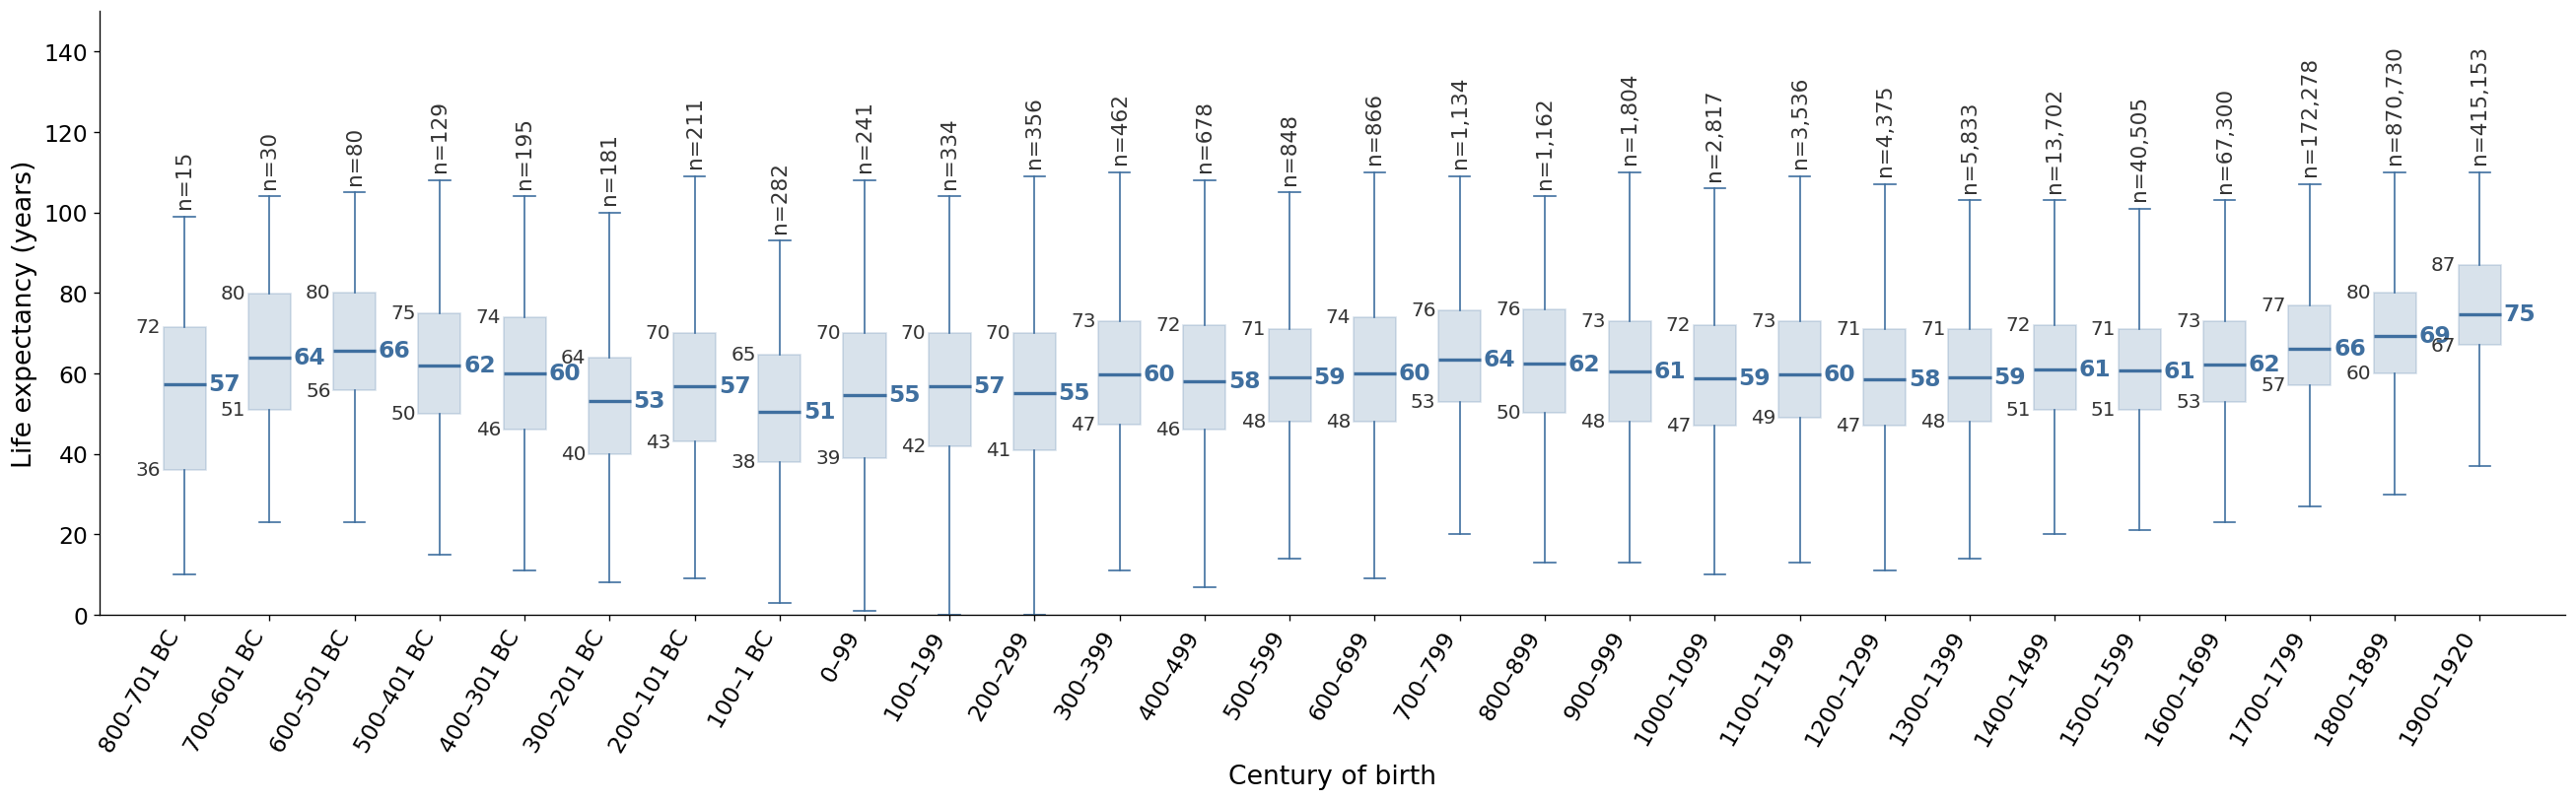

In [11]:
fig, ax = plt.subplots(figsize=(22, 7))
plot_boxes(ax, analysed, MAIN_LINE_COLOR)
ax.set_xlabel('Century of birth')
plt.tight_layout()
plt.show()

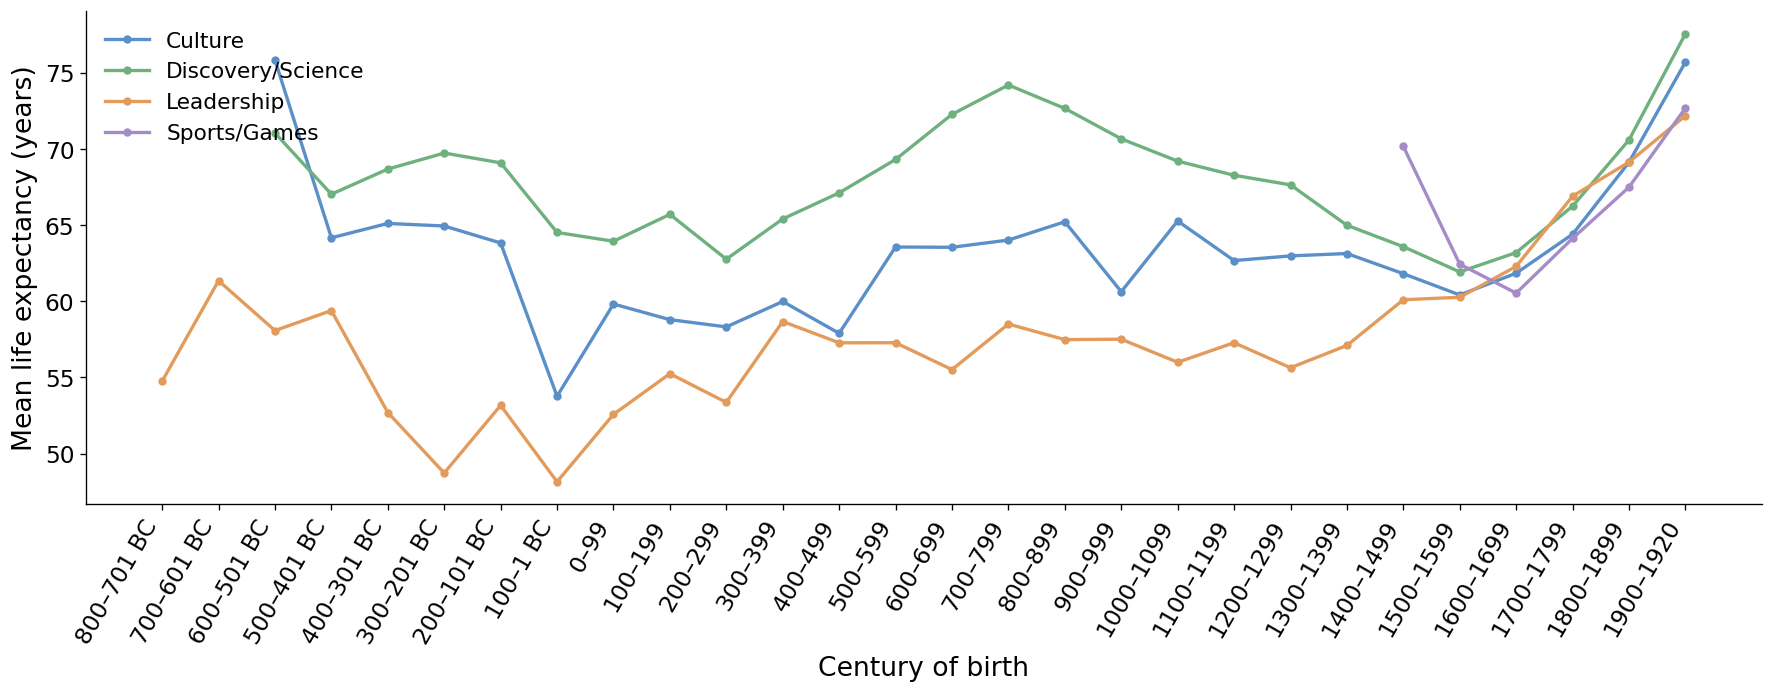

In [12]:
occupation_means = (
    analysed.group_by('meta_occupation', 'birth_century')
    .agg(pl.len().alias('individuals'), pl.col('life_expectancy').mean().alias('mean'))
    .filter(pl.col('individuals') >= MIN_LIVES)
    .sort('birth_century')
)
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for occupation, color in OCCUPATION_COLORS.items():
    rows = occupation_means.filter(pl.col('meta_occupation') == occupation)
    ax.plot(rows['birth_century'], rows['mean'], color=color, linewidth=2, marker='o', markersize=4, label=occupation)
set_century_axis(ax, sorted(occupation_means['birth_century'].unique().to_list()))
ax.set_ylabel('Mean life expectancy (years)')
ax.set_xlabel('Century of birth')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3. Cohorts: mean life expectancy per meta occupation and century

In [13]:
def cohorts(anchor, wanted):
    stats = (pl.len().alias('individuals'), pl.col('life_expectancy').mean().alias('mean'))
    cells = pl.concat([
        lives.group_by('meta_occupation', pl.col(anchor).alias('century')).agg(*stats),
        lives.group_by(pl.col(anchor).alias('century')).agg(*stats).select(pl.lit(ALL).alias('meta_occupation'), 'century', 'individuals', 'mean'),
    ])
    large = cells.filter(pl.col('individuals') >= MIN_LIVES).select('meta_occupation', pl.col('century').alias('used century'), pl.col('mean').alias('used mean'))
    return (
        wanted.join(large, on='meta_occupation')
        .with_columns((pl.col('used century') - pl.col('century')).abs().alias('distance'))
        .sort('distance', 'used century', descending=[False, True])
        .group_by('meta_occupation', 'century', maintain_order=True).first()
        .join(cells.select('meta_occupation', 'century', 'individuals'), on=['meta_occupation', 'century'], how='left')
        .with_columns(pl.col('individuals').fill_null(0))
        .select('meta_occupation', 'century', 'individuals', 'used century', 'used mean')
        .sort('meta_occupation', 'century')
    )


death_targets = missing_death.filter(pl.col('birth_year') + OLDEST_AGE < CURRENT_YEAR).with_columns((pl.col('birth_year') // CENTURY * CENTURY).alias('century'))
birth_targets = missing_birth.with_columns((pl.col('death_year') // CENTURY * CENTURY).alias('century'))
death_cohorts = cohorts('birth_century', death_targets.select('meta_occupation', 'century').unique())
birth_cohorts = cohorts('death_century', birth_targets.select('meta_occupation', 'century').unique())

In [14]:
death_cohorts.filter(pl.col('century') >= FIRST_CENTURY).with_columns(pl.col('used mean').round(1))

meta_occupation,century,individuals,used century,used mean
str,i64,u32,i64,f64
"""All""",-800,15,-800,57.3
"""All""",-700,30,-700,63.9
"""All""",-600,80,-600,65.7
"""All""",-500,129,-500,62.0
"""All""",-400,195,-400,60.0
"""All""",-300,181,-300,53.3
"""All""",-200,211,-200,56.9
"""All""",-100,282,-100,50.5
"""All""",0,241,0,54.7


In [15]:
birth_cohorts.filter(pl.col('century') >= FIRST_CENTURY).with_columns(pl.col('used mean').round(1))

meta_occupation,century,individuals,used century,used mean
str,i64,u32,i64,f64
"""All""",-800,6,-700,58.0
"""All""",-700,18,-700,58.0
"""All""",-600,36,-600,60.9
"""All""",-500,113,-500,64.9
"""All""",-400,162,-400,56.8
"""All""",-300,203,-300,57.8
"""All""",-200,163,-200,56.1
"""All""",-100,292,-100,51.2
"""All""",0,272,0,51.9


## 4. Estimated dates

In [16]:
check_death = death_targets.join(death_cohorts, on=['meta_occupation', 'century']).with_columns((pl.col('birth_year') + pl.col('used mean').round()).cast(pl.Int64).alias('estimated year'))
check_birth = birth_targets.join(birth_cohorts, on=['meta_occupation', 'century']).with_columns((pl.col('death_year') - pl.col('used mean').round()).cast(pl.Int64).alias('estimated year'))
assert check_death.height == death_targets.height and check_birth.height == birth_targets.height

summary = []
for missing_date, frame, targets, check in [('death', missing_death, death_targets, check_death), ('birth', missing_birth, birth_targets, check_birth)]:
    borrowed = check.filter(pl.col('used century') != pl.col('century'))
    summary.append({
        'missing': missing_date,
        'missing, with the other date': frame.height,
        'can be estimated': targets.height,
        'estimated': check.height,
        '% of missing estimated': round(100 * check.height / frame.height, 1),
        'from a borrowed century': borrowed.height,
        'mean estimated life expectancy': round(check['used mean'].mean(), 1),
    })
pl.DataFrame(summary)

missing,"missing, with the other date",can be estimated,estimated,% of missing estimated,from a borrowed century,mean estimated life expectancy
str,i64,i64,i64,f64,i64,f64
"""death""",4130793,368458,368458,8.9,60,68.7
"""birth""",258435,258435,258435,100.0,116,65.7


In [17]:
pl.concat([
    check_death.sample(5, seed=42).select(pl.lit('death').alias('missing'), 'qid', 'meta_occupation', pl.col('birth_year').alias('remaining year'), 'estimated year', 'used century', pl.col('used mean').round(1)),
    check_birth.sample(5, seed=42).select(pl.lit('birth').alias('missing'), 'qid', 'meta_occupation', pl.col('death_year').alias('remaining year'), 'estimated year', 'used century', pl.col('used mean').round(1)),
])

missing,qid,meta_occupation,remaining year,estimated year,used century,used mean
str,str,str,i64,i64,i64,f64
"""death""","""Q45577537""","""All""",1855,1924,1800,69.4
"""death""","""Q113716289""","""All""",1724,1790,1700,66.1
"""death""","""Q95238311""","""Discovery/Science""",1911,1989,1900,77.6
"""death""","""Q133485191""","""All""",1624,1686,1600,62.3
"""death""","""Q43199586""","""Discovery/Science""",1893,1964,1800,70.6
"""birth""","""Q76166700""","""All""",1875,1811,1800,63.8
"""birth""","""Q112671949""","""Culture""",2022,1930,2000,91.7
"""birth""","""Q95310658""","""All""",1737,1675,1700,62.3
"""birth""","""Q75823504""","""All""",1940,1869,1900,71.0


## 5. Test on a held-out 20%

The simplest model: one global mean life expectancy, learned on a random 80% of the individuals with both dates. The death of each of the other 20% is estimated as birth year + that mean, and is good when it falls within 10 years of the true death.

In [18]:
SEED = 42
TRAIN_SHARE = 0.8
WITHIN = 10

shuffled = lives.sample(fraction=1, shuffle=True, seed=SEED)
cut = int(TRAIN_SHARE * shuffled.height)
train, test = shuffled[:cut], shuffled[cut:]
assert train.height + test.height == lives.height and test.join(train, on='qid').height == 0
print(f'train: {train.height:,} individuals ({100 * train.height / lives.height:.0f}%), test: {test.height:,} individuals ({100 * test.height / lives.height:.0f}%)')

train: 1,284,241 individuals (80%), test: 321,061 individuals (20%)


In [19]:
mean_life = train['life_expectancy'].mean()
estimated = test.with_columns((pl.col('birth_year') + round(mean_life)).alias('estimated death')).with_columns(
    (pl.col('estimated death') - pl.col('death_year')).alias('error'),
)
print(f'global mean life expectancy: {mean_life:.1f} years')
estimated.select('qid', 'meta_occupation', 'birth_year', 'death_year', 'estimated death', 'error').sample(5, seed=SEED)

global mean life expectancy: 69.7 years


qid,meta_occupation,birth_year,death_year,estimated death,error
str,str,i64,i64,i64,i64
"""Q23818746""","""Leadership""",1912,1998,1982,-16
"""Q2226448""","""Culture""",1872,1932,1942,10
"""Q112503477""","""Leadership""",1854,1920,1924,4
"""Q2830927""","""Leadership""",1818,1901,1888,-13
"""Q114394545""","""Leadership""",1848,1914,1918,4


### Accuracy

Error = estimated − true death year; a positive bias means the estimates are too late.

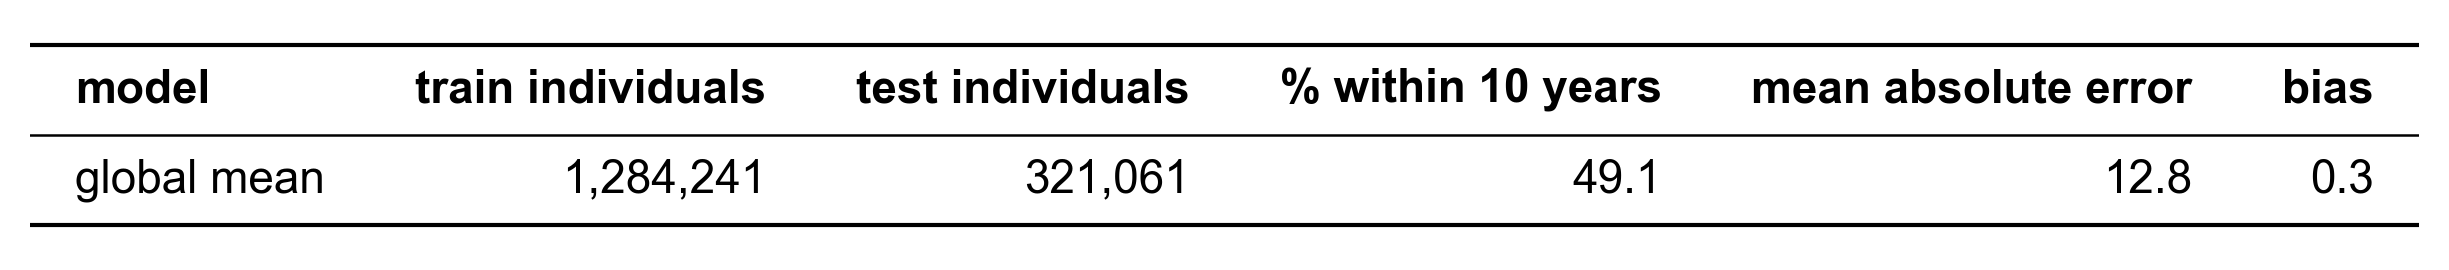

In [20]:
def accuracy(frame, *by):
    return frame.group_by(*by, maintain_order=True).agg(
        pl.len().alias('individuals'),
        (100 * (pl.col('error').abs() <= WITHIN).mean()).alias(f'% within {WITHIN} years'),
        pl.col('error').abs().mean().alias('mean absolute error'),
        pl.col('error').mean().alias('bias'),
    )


result = accuracy(estimated.with_columns(pl.lit('global mean').alias('model')), 'model').rename({'individuals': 'test individuals'})
show_table(result.insert_column(1, pl.Series('train individuals', [train.height])), decimals=1)

### Figure: % of deaths within 10 years per century of birth, global mean

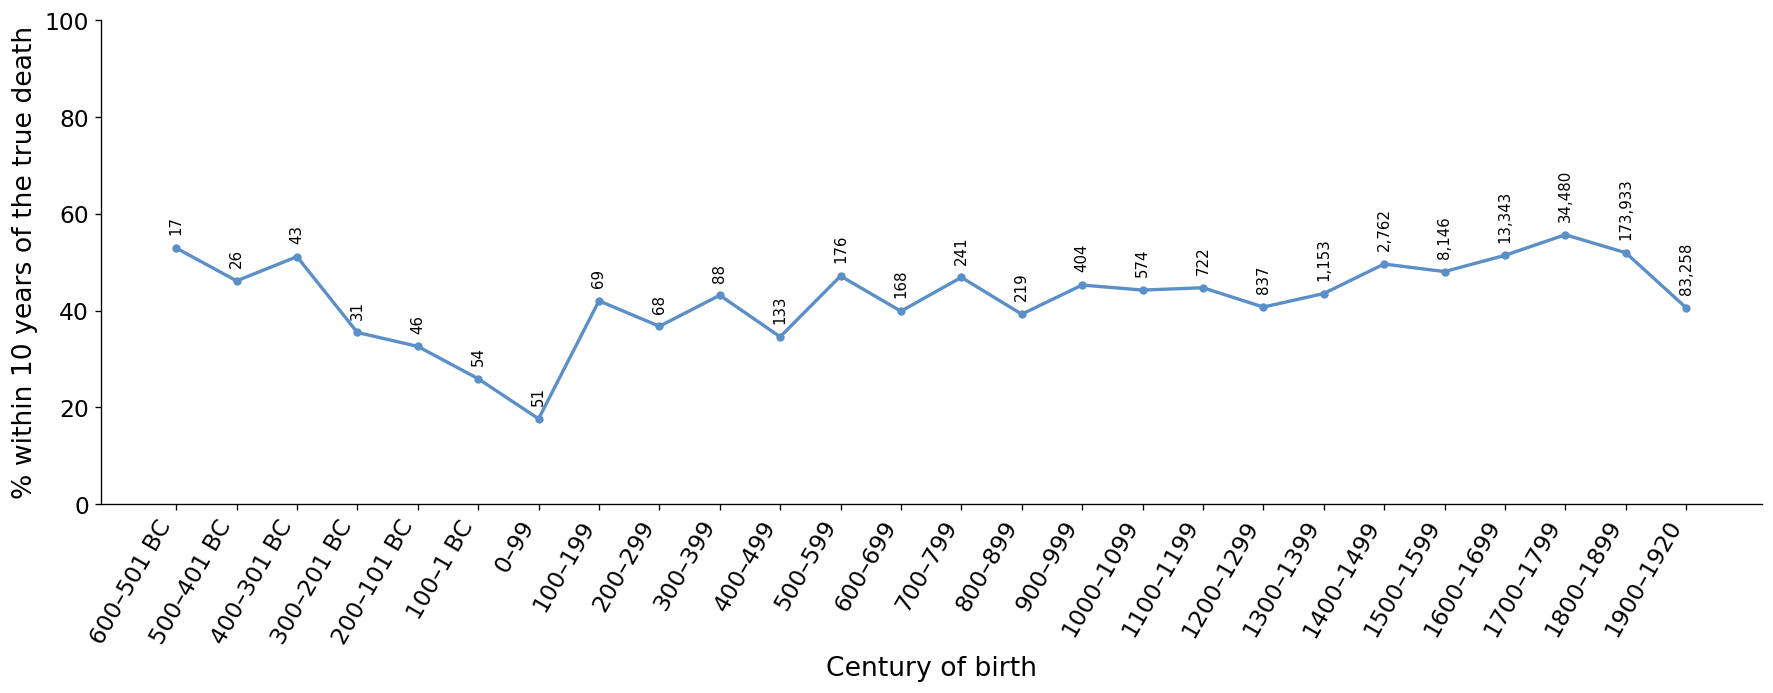

In [21]:
per_century = (
    accuracy(estimated.filter(pl.col('birth_century').is_between(FIRST_CENTURY, LAST_BIRTH_CENTURY)), 'birth_century')
    .filter(pl.col('individuals') >= MIN_LIVES)
    .sort('birth_century')
)
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.plot(per_century['birth_century'], per_century[f'% within {WITHIN} years'], color=BLUE, linewidth=2, marker='o', markersize=4)
for century, share, tested in per_century.select('birth_century', f'% within {WITHIN} years', 'individuals').iter_rows():
    ax.annotate(f'{tested:,}', (century, share), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, rotation=90, va='bottom')
set_century_axis(ax, per_century['birth_century'].to_list())
ax.set_ylim(0, 100)
ax.set_ylabel(f'% within {WITHIN} years of the true death')
ax.set_xlabel('Century of birth')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()